CAST test


In [72]:
import CAST
import scanpy as sc
import torch, os
import numpy as np
from os.path import join as pj
import warnings
warnings.filterwarnings("ignore")

output_path = 'results/71and72/' #### input the demo path
os.makedirs(output_path,exist_ok=True)

In [73]:
sliceA = sc.read_h5ad("../PASTE/DLFPC/data/151671_preprocessed.h5")
xy = np.asarray(sliceA.obsm["spatial"])  # works whether it's stored as an array or a DataFrame
sliceA.obs["column"] = xy[:, 0]  # x: horizontal pixel position
sliceA.obs["row"] = xy[:, 1]     # y: vertical pixel position
sliceB = sc.read_h5ad("../PASTE/DLFPC/data/151672_preprocessed.h5")
xy = np.asarray(sliceB.obsm["spatial"])  # works whether it's stored as an array or a DataFrame
sliceB.obs["column"] = xy[:, 0]  # x: horizontal pixel position
sliceB.obs["row"] = xy[:, 1]     # y: vertical pixel position

In [74]:
## Make gene names unique by adding freuqency counts to duplicates

def make_unique(s):
    if s in counts:
        counts[s] += 1
    else:
        counts[s] = 0
    return s if counts[s] == 0 else f"{s}_{counts[s]}"

counts = {}
sliceA.var.index = sliceA.var.index.map(make_unique)
counts = {}
sliceB.var.index = sliceB.var.index.map(make_unique)

In [75]:
from CAST.utils import detect_highly_variable_genes

# combine the two datasets
sample_list= ['Visium1','Visium2'] # [Query, Reference]
sdata = sliceA.concatenate(sliceB)

# rename the dataset labels to Visium1 and Visium2
batch_key = 'batch'
batch_rename = {'0' : sample_list[0],'1' : sample_list[1]}
sdata.obs.replace({batch_key:batch_rename},inplace=True)

# Filter for highly variable genes
sdata.var['highly_variable'] = detect_highly_variable_genes(sdata,batch_key=batch_key,n_top_genes=4000,count_layer='.X')
sdata = sdata[:,sdata.var['highly_variable']]

# Output the combined dataset
sdata.write_h5ad(f'{output_path}/Visium_vs_Visium.h5ad')

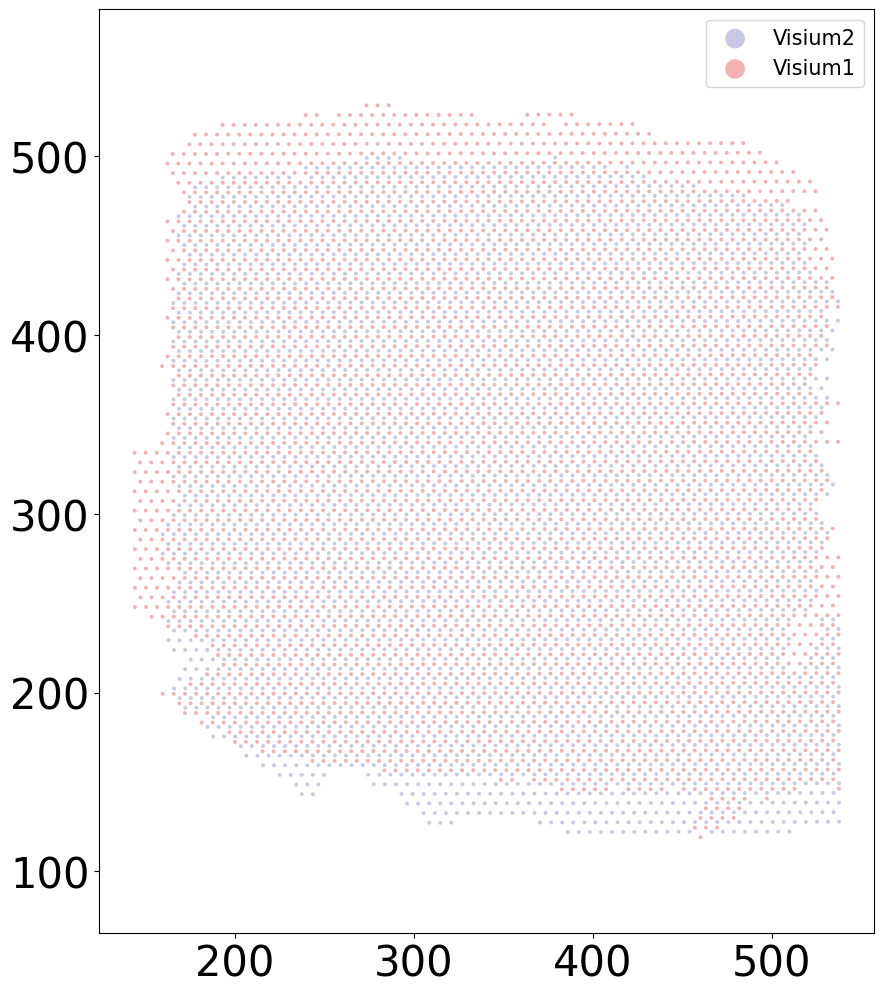

In [76]:
from CAST.visualize import plot_mid

coords_t = np.array(sdata.obs[['column', 'row']])
plot_mid(coords_t[sdata.obs[batch_key] == sample_list[0]],
         coords_t[sdata.obs[batch_key] == sample_list[1]],
         output_path=output_path,
         filename = 'Align_raw',
         title_t = [sample_list[1],
                    sample_list[0]],
         s_t = 8,scale_bar_t = None)

In [77]:
from CAST.utils import extract_coords_exp
coords_raw,exps = extract_coords_exp(sdata, batch_key = 'batch', cols = ['column', 'row'], count_layer = '.X', data_format = 'norm1e4')
torch.save(coords_raw, f'{output_path}/coords_raw.pt')

Preprocessing...


Constructing delaunay graphs for 2 samples...
Training on cpu...


Loss: -411.862 step time=1.016s: 100%|██████████| 400/400 [05:50<00:00,  1.14it/s]


Finished.
The embedding, log, model files were saved to results/71and72/
Perform KMeans clustering on 7980 cells...
Plotting the KMeans clustering results...


array([15,  9,  0, ...,  5,  1,  4], dtype=int32)

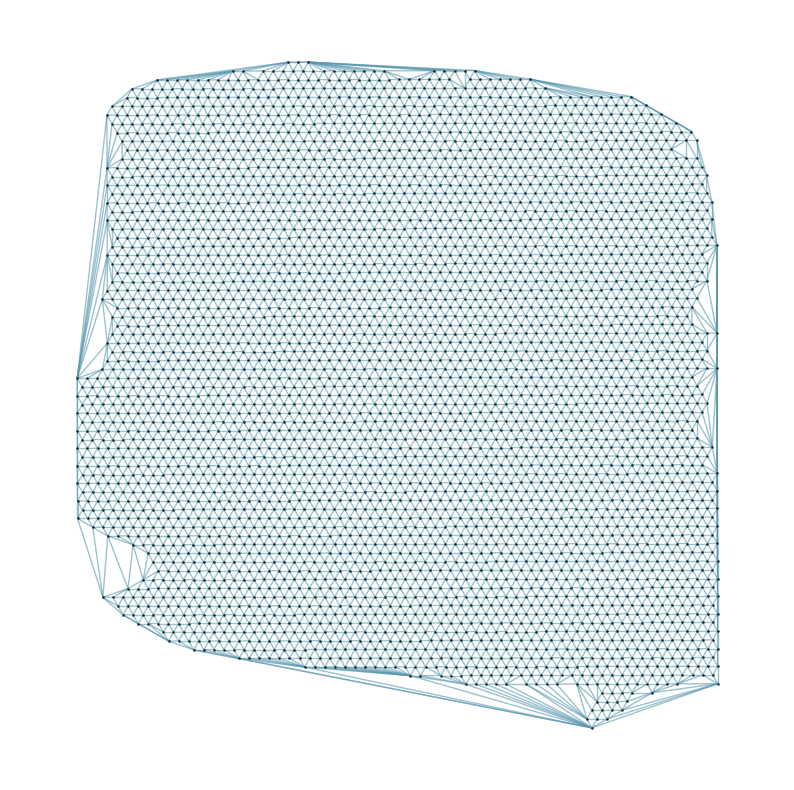

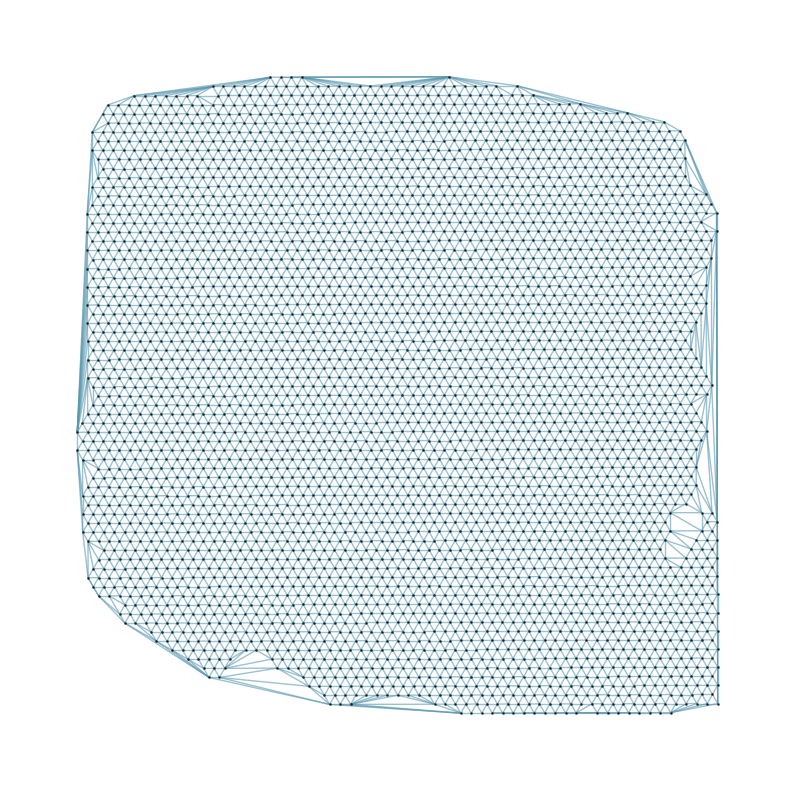

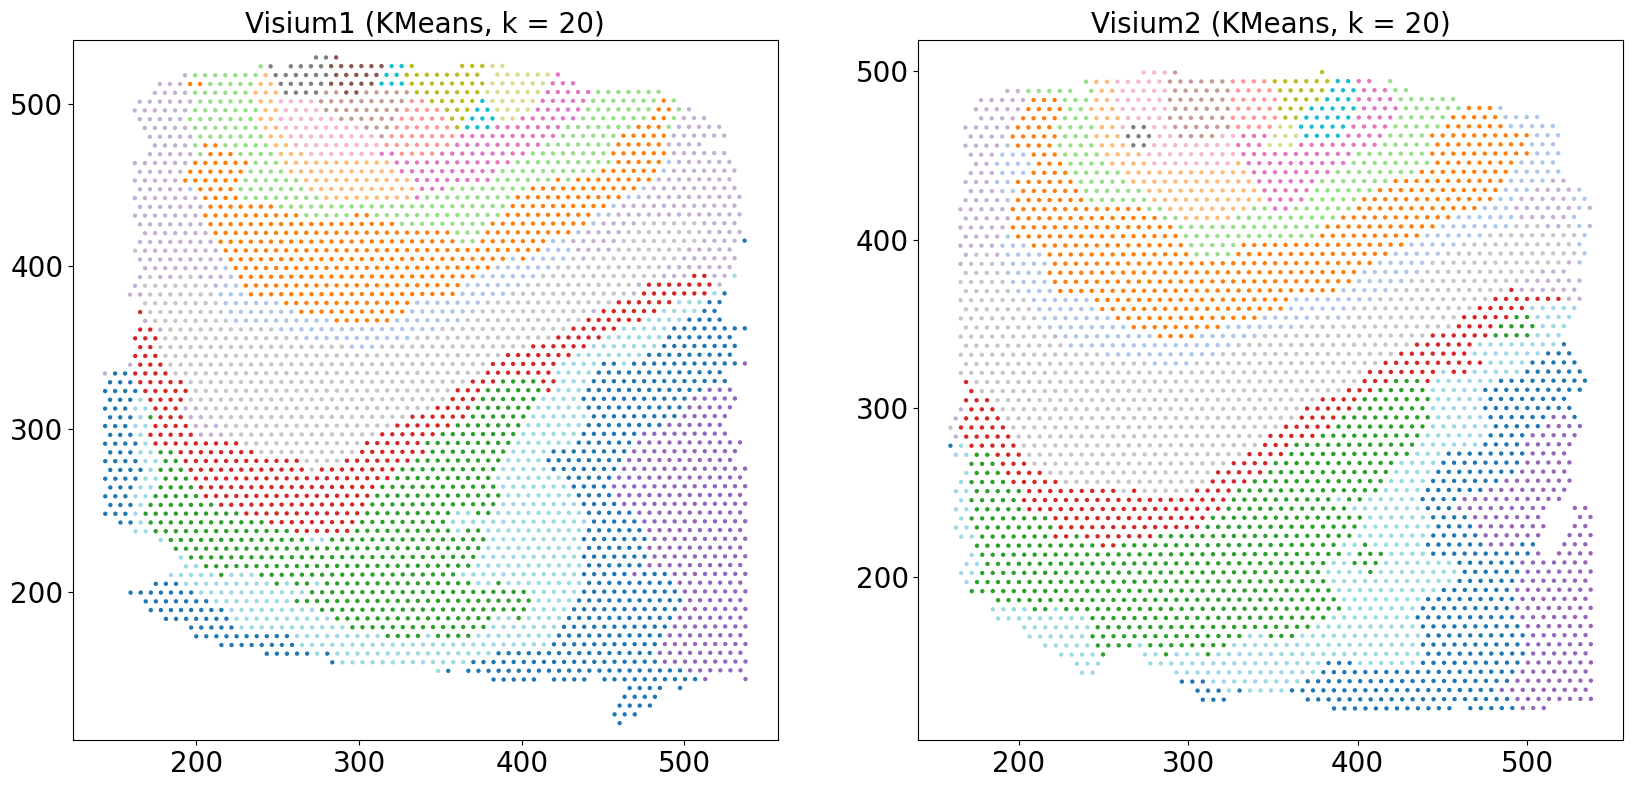

In [78]:
## Run CAST Mark — capture common spatial features

from CAST.models.model_GCNII import Args
from CAST import CAST_MARK
from CAST.visualize import kmeans_plot_multiple

# set the parameters for CAST Mark
args = Args(
    dataname='task1', # name of the dataset, used to save the log file
    gpu = 0, # gpu id, set to zero for single-GPU nodes
    epochs=400, # number of epochs for training
    lr1= 1e-3, # learning rate
    wd1= 0, # weight decay
    lambd= 1e-3, # lambda in the loss function, refer to online methods
    n_layers=2, # number of GCNII layers, more layers mean a deeper model, larger reception field, at a cost of VRAM usage and computation time
    der=0.5, # edge dropout rate in CCA-SSG
    dfr=0.3, # feature dropout rate in CCA-SSG
    use_encoder=True, # perform a single-layer dimension reduction before the GNNs, helps save VRAM and computation time if the gene panel is large
    encoder_dim=512, # encoder dimension, ignore if `use_encoder` set to `False`
)

# run CAST Mark
embed_dict = CAST_MARK(coords_raw,exps,output_path,args = args,graph_strategy='delaunay')

# plot the results
kmeans_plot_multiple(embed_dict,sample_list,coords_raw,'demo1',output_path,k=20,dot_size = 10,minibatch=True)

100%|██████████| 1/1 [00:00<00:00, 151.29it/s]


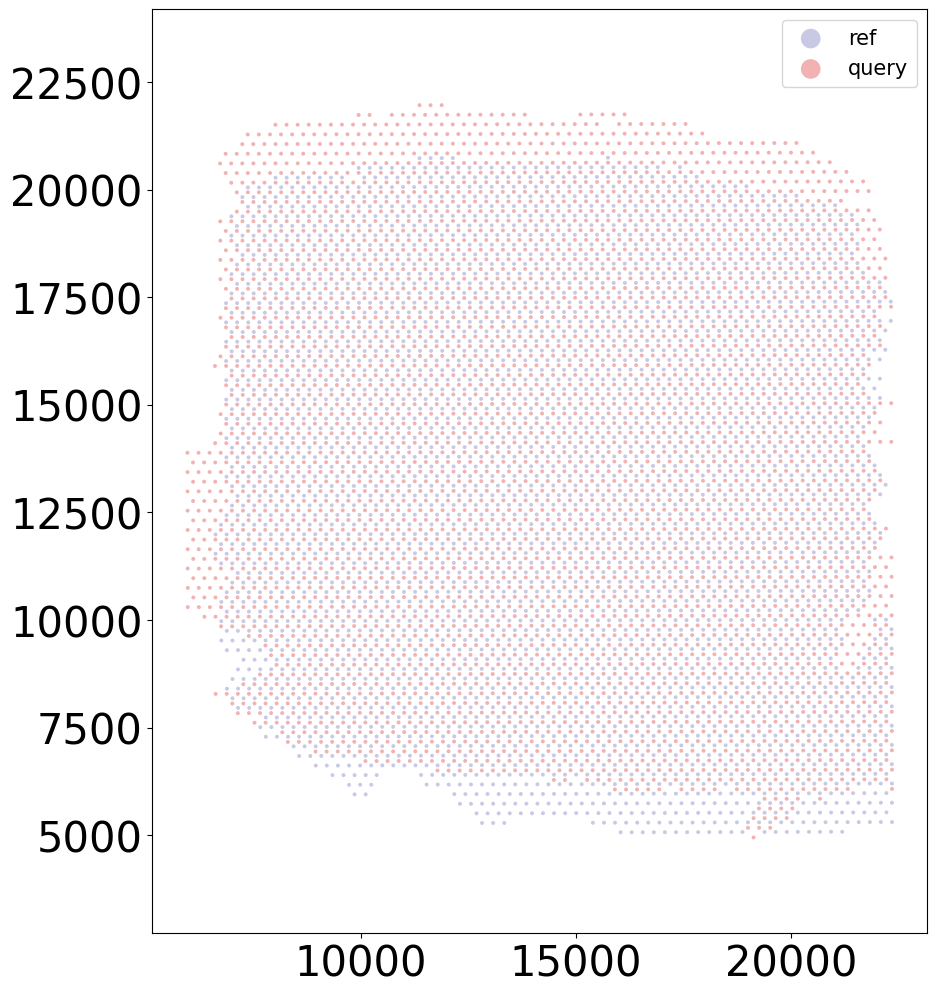

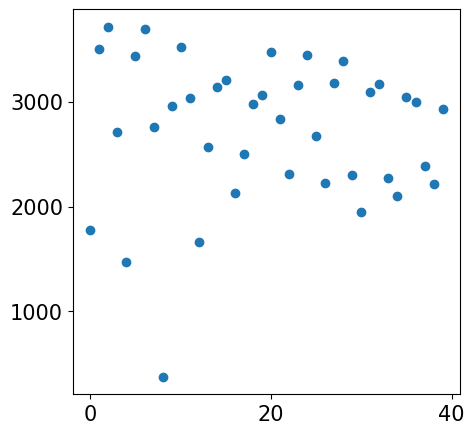

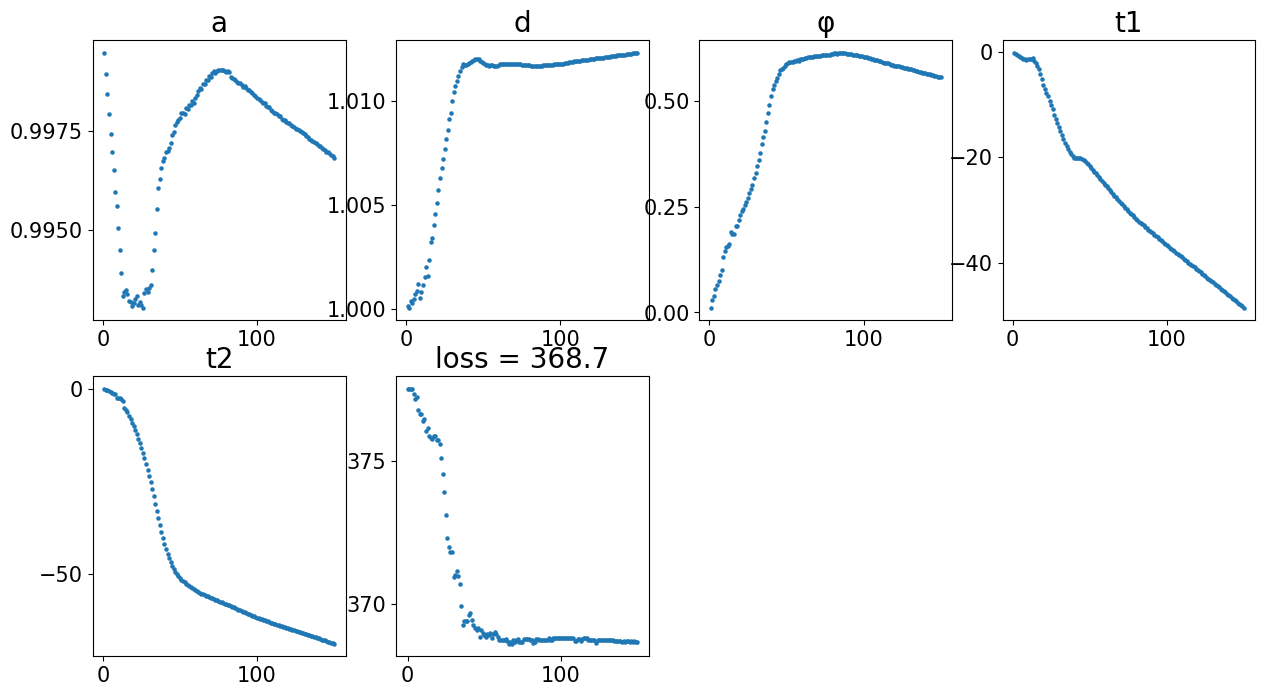

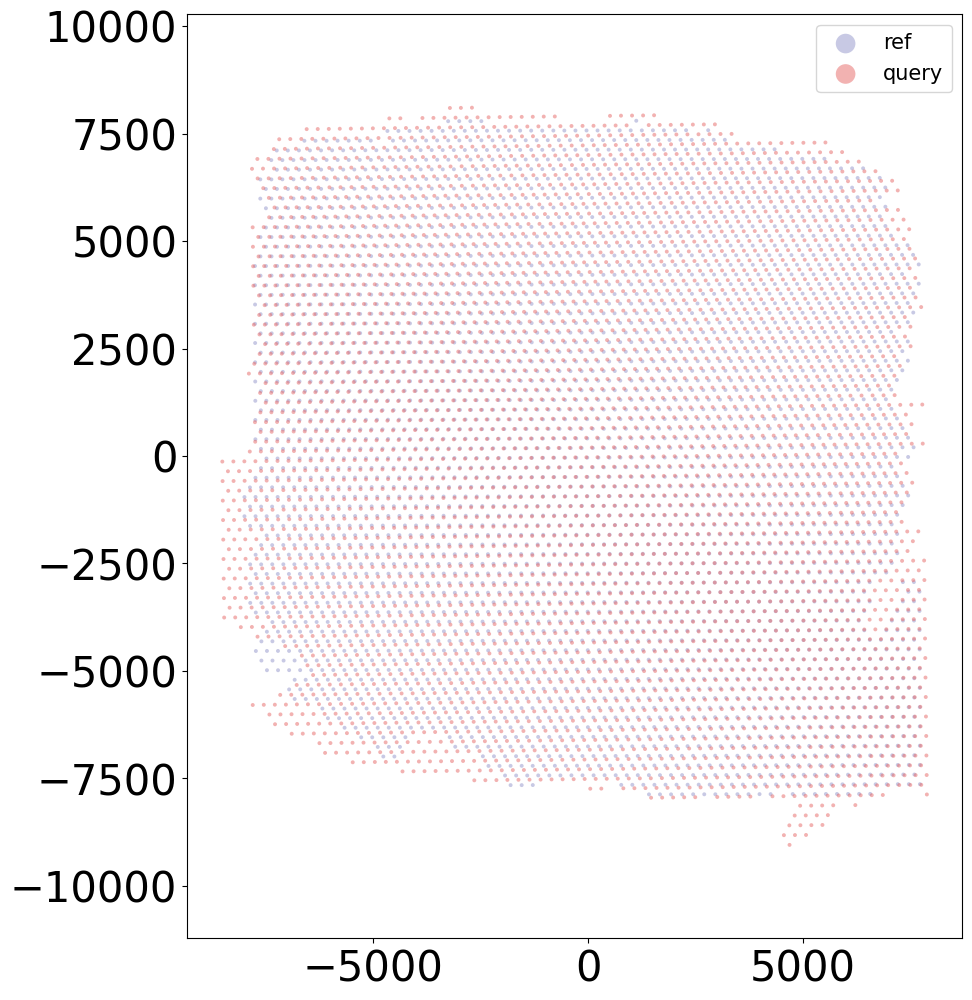

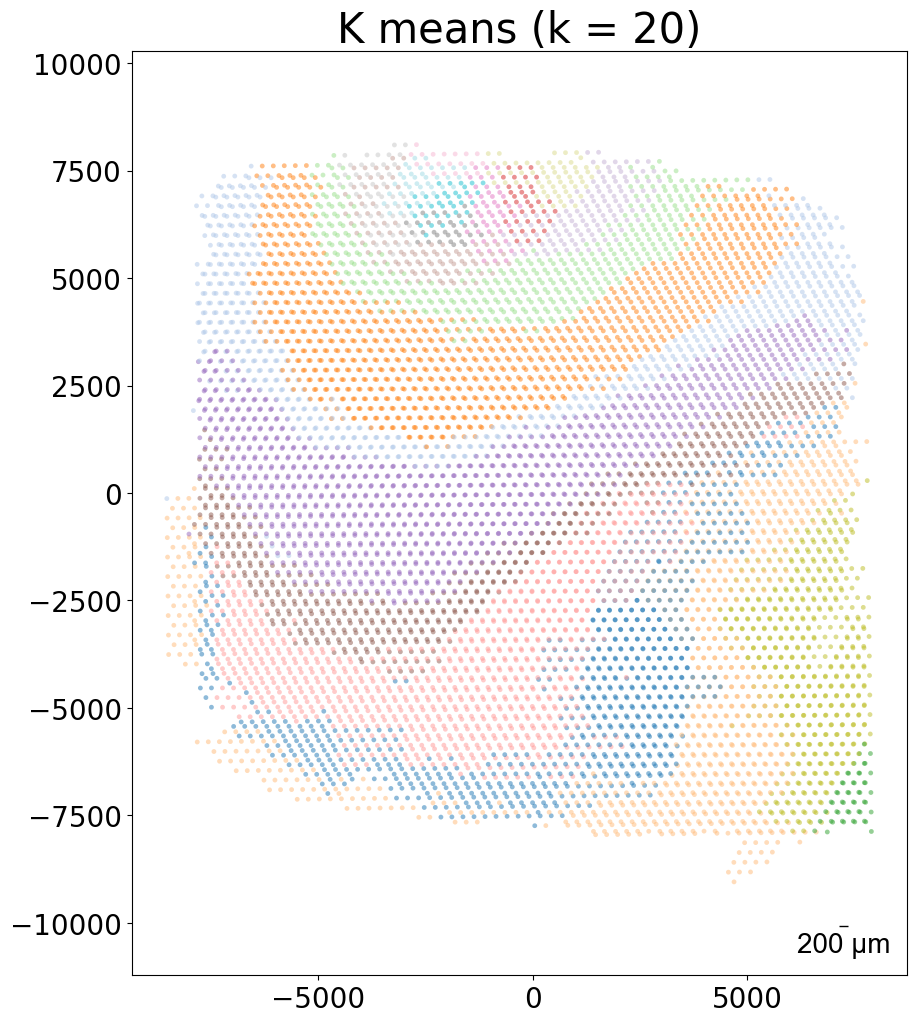

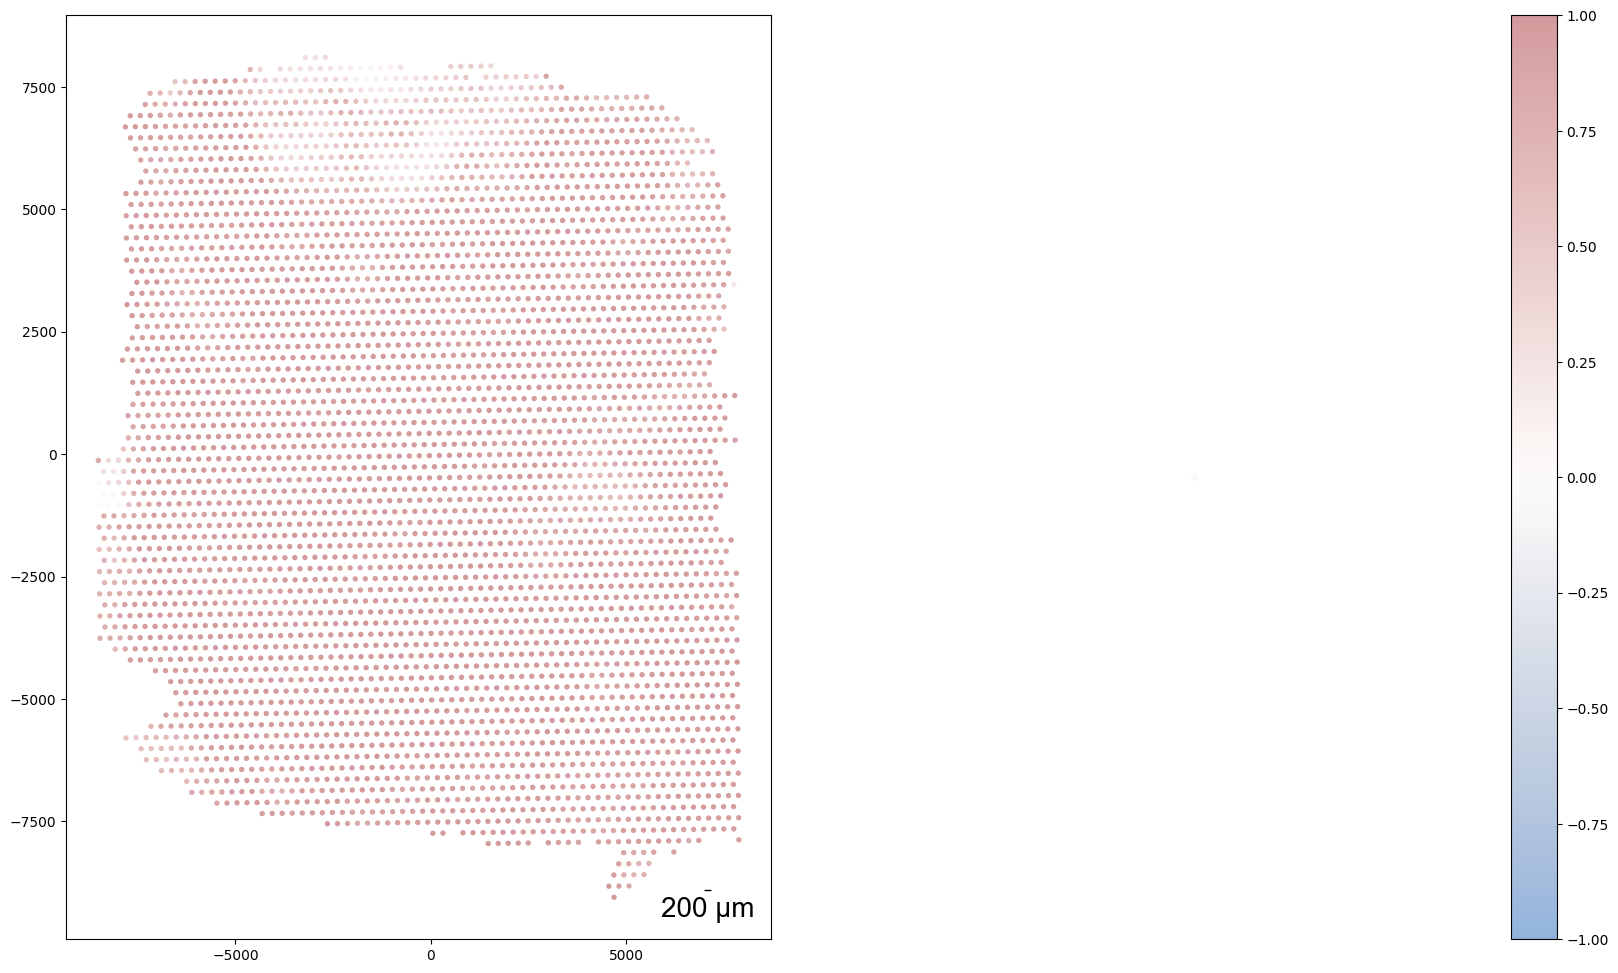

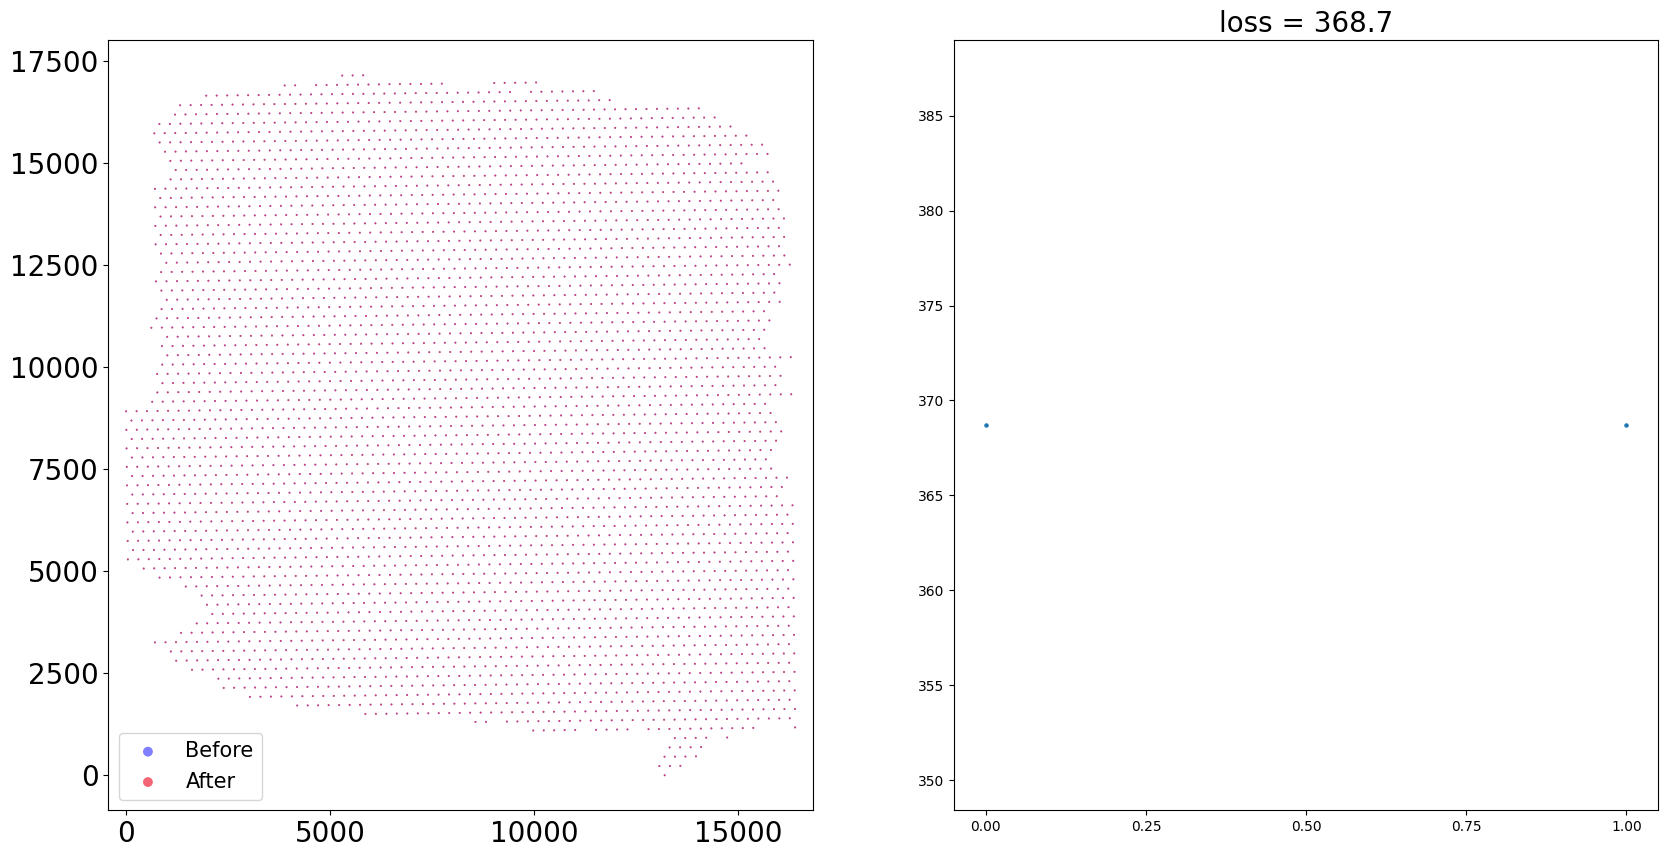

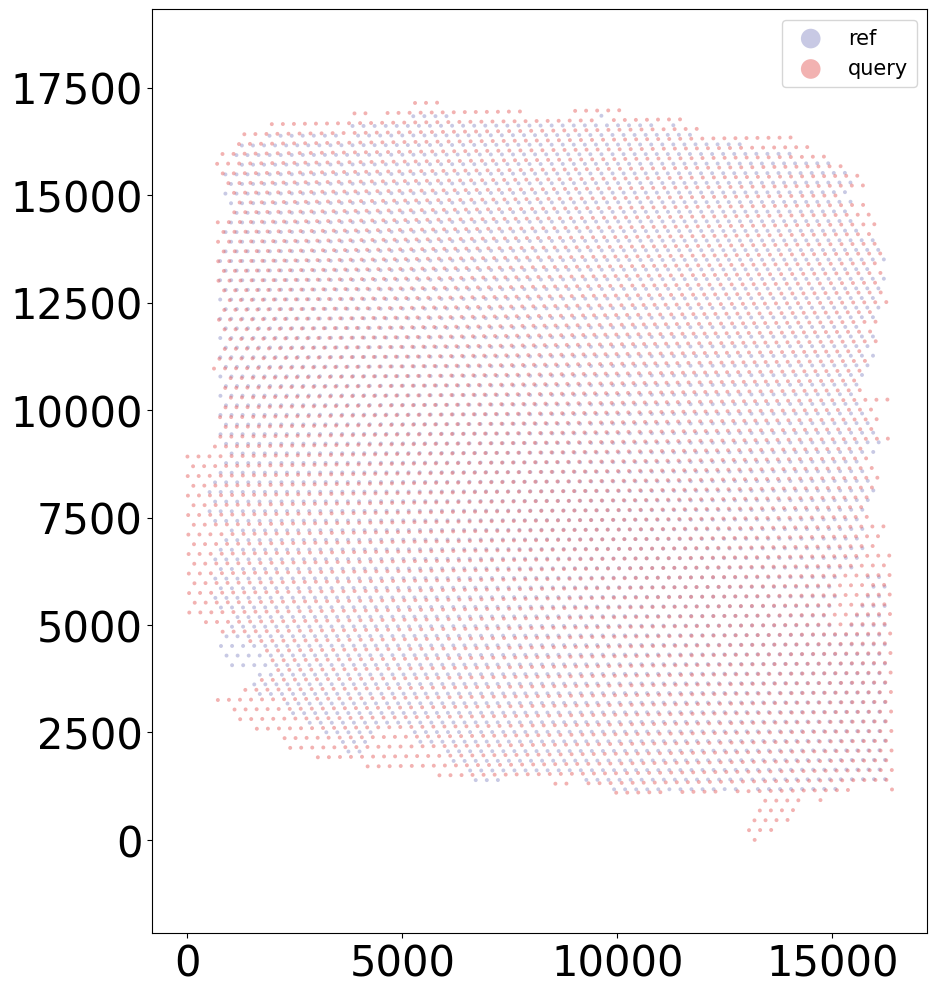

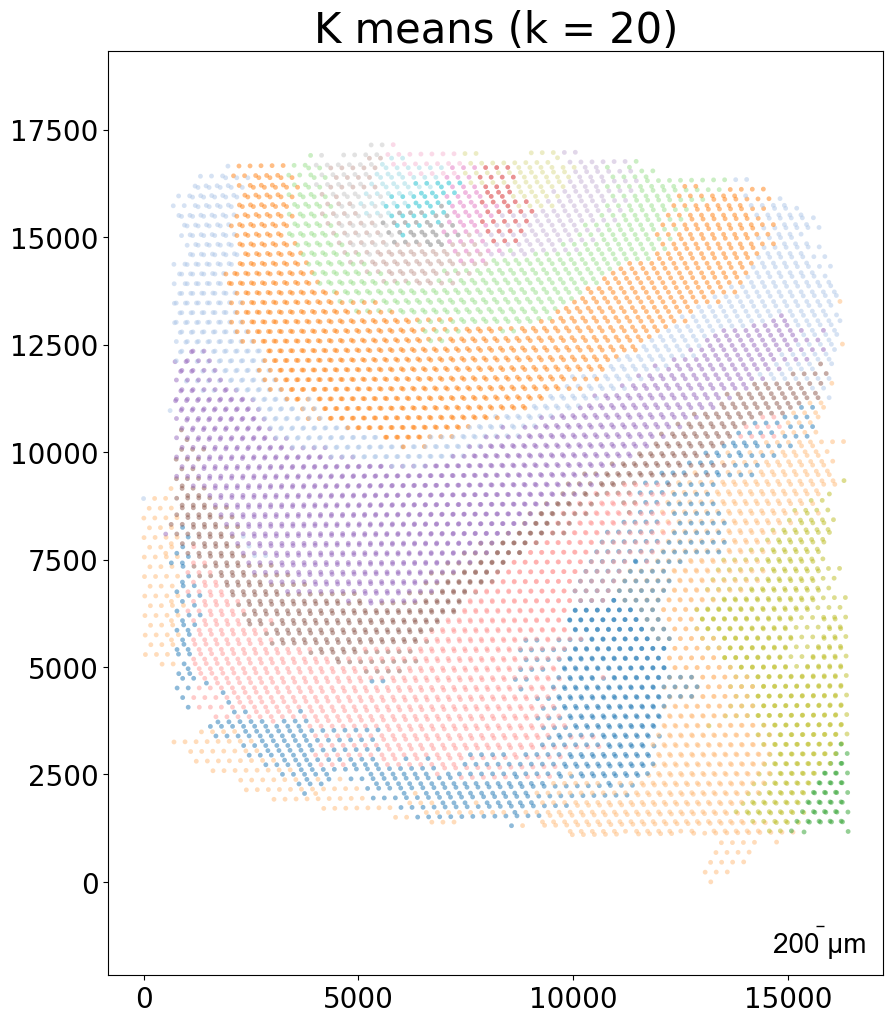

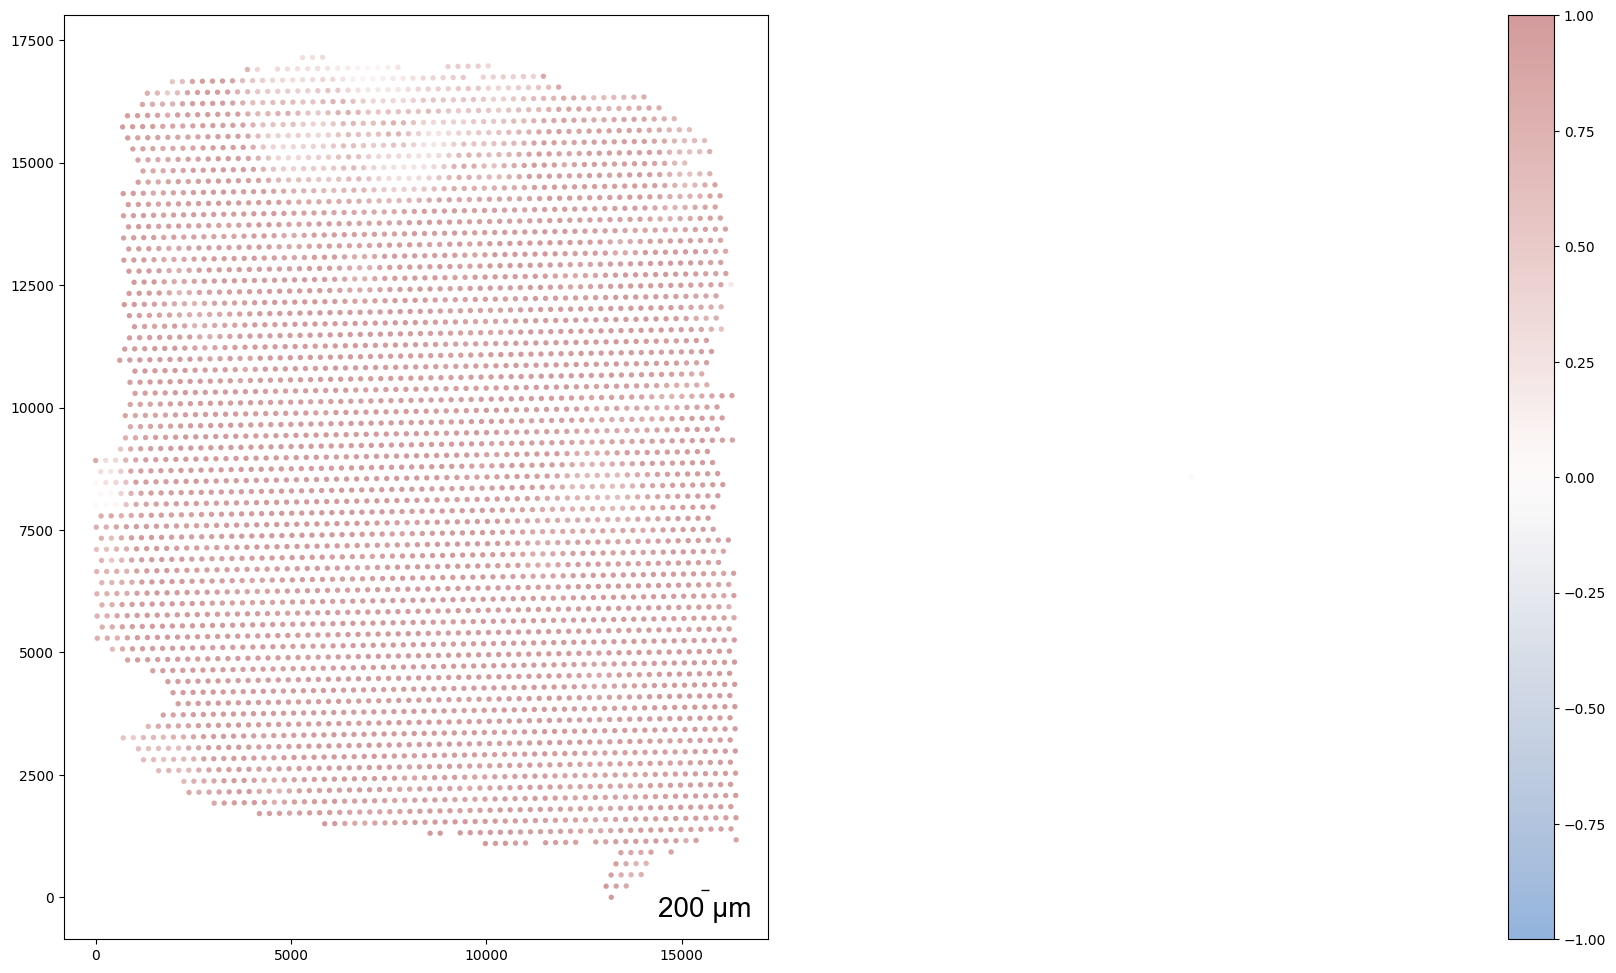

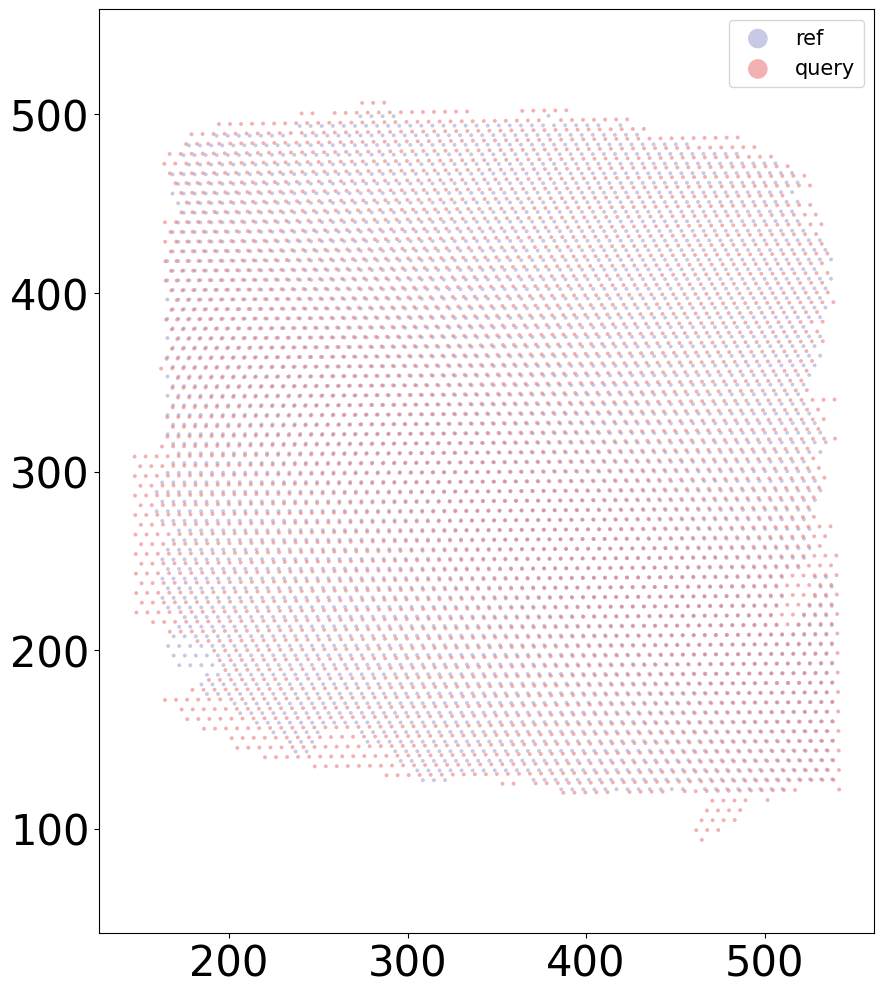

In [79]:
## Run CAST Stack — align the two samples

from CAST.CAST_Stack import reg_params
from CAST import CAST_STACK

# set the parameters for CAST Stack
query_sample = sample_list[0]
params_dist = reg_params(dataname = query_sample,
                            gpu = 0 if torch.cuda.is_available() else -1,
                            #### Affine parameters
                            iterations=150,
                            dist_penalty1=0,
                            bleeding=500,
                            d_list = [3,2,1,1/2,1/3],
                            attention_params = [None,3,1,0],
                            #### FFD parameters
                            dist_penalty2 = [0],
                            alpha_basis_bs = [0],
                            meshsize = [8],
                            iterations_bs = [1],
                            attention_params_bs = [[None,3,1,0]],
                            mesh_weight = [None])
# set the alpha basis for the affine transformation
params_dist.alpha_basis = torch.Tensor([1/1000,1/1000,1/50,5,5]).reshape(5,1).to(params_dist.device)

# run CAST Stack
coord_final = CAST_STACK(coords_raw,embed_dict,output_path,sample_list,params_dist,sub_node_idxs = None, rescale = True)

Perform KMeans clustering on 7980 cells...
Plotting the KMeans clustering results...
Perform KMeans clustering on 7980 cells...
Plotting the KMeans clustering results...


array([15,  9,  0, ...,  5,  1,  4], dtype=int32)

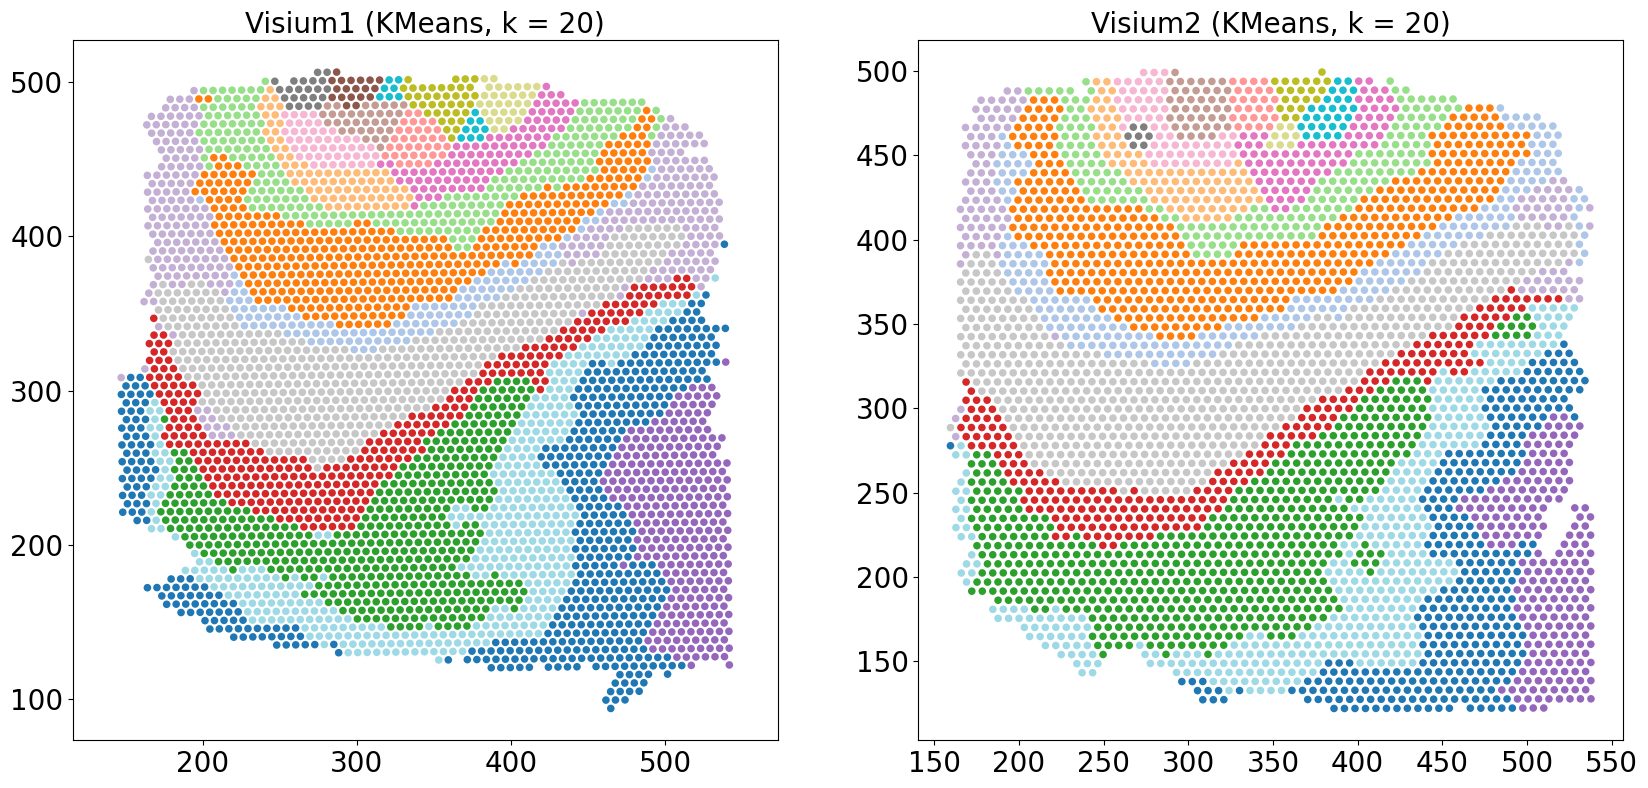

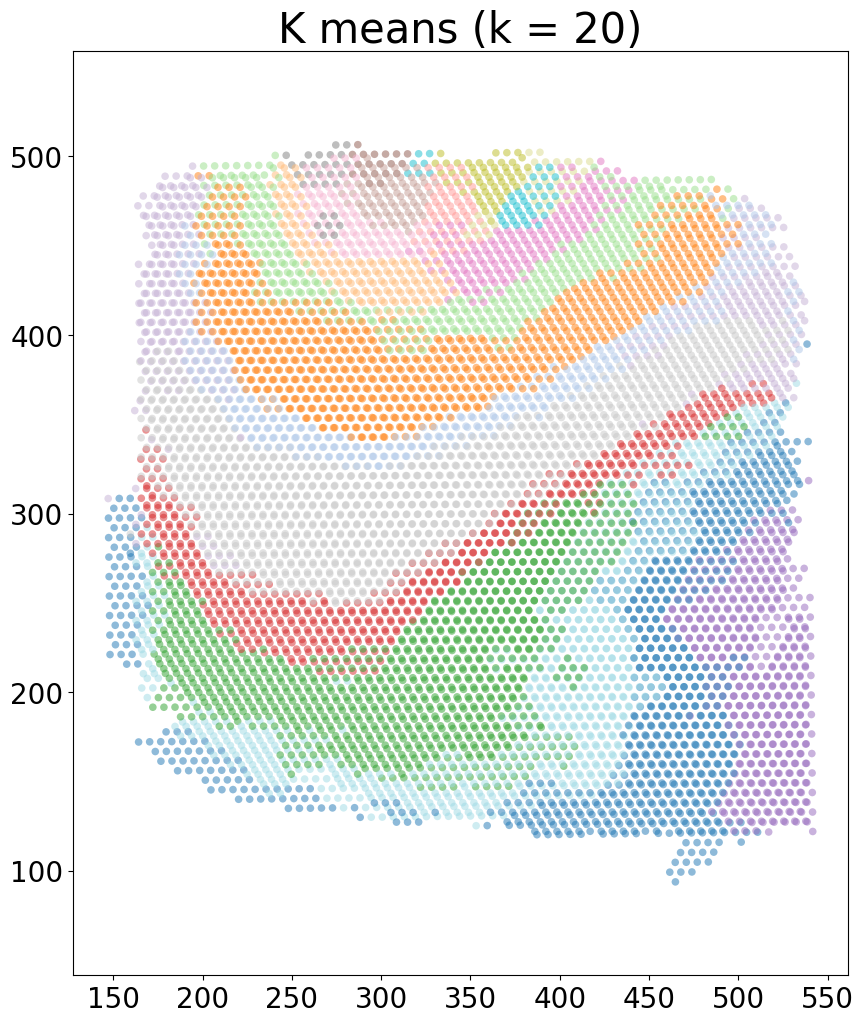

In [80]:
from CAST.visualize import kmeans_plot_multiple

# Side-by-side plots
kmeans_plot_multiple(embed_dict,sample_list,coord_final,'demo1_new',output_path,k=20,dot_size = 30,minibatch=True)

# Overlay plot
kmeans_plot_multiple(embed_dict,sample_list,coord_final,'demo1_new',output_path,k=20,dot_size = 30,minibatch=True,plot_strategy='stack')

In [81]:
np.asarray(coord_final["Visium1"])

array([[461.58276, 366.69107],
       [204.56306, 412.77942],
       [439.17014, 169.85641],
       ...,
       [230.21024, 336.64227],
       [271.66937, 490.04523],
       [306.75986, 130.10388]], dtype=float32)

In [82]:
sliceA.obsm["spatial"] = np.asarray(coord_final["Visium1"])
sliceB.obsm["spatial"] = np.asarray(coord_final["Visium2"])
sliceA.write_h5ad(f'{output_path}/151671adata_aligned.h5ad')
sliceB.write_h5ad(f'{output_path}/151672adata_aligned.h5ad')